# Задание 7. Baseline-модель SMS

Logistic Regression внутри Pipeline с признаками задания 6. Метрики считаются на **валидационной** выборке; тестовая не используется.

In [1]:
# Настройка путей. Работает локально и в Google Colab.
import sys
import zipfile
from pathlib import Path

if "google.colab" in sys.modules and not Path("ml").exists():
    # В Colab загрузите архив проекта sms_guard_colab.zip (см. README).
    from google.colab import files
    uploaded = files.upload()
    zipfile.ZipFile(next(iter(uploaded))).extractall(".")

ROOT = Path.cwd() if (Path.cwd() / "ml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print("Корень проекта:", ROOT.name)

Корень проекта: AIproject


In [2]:
import json
from datetime import date

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score, precision_score, recall_score,
)

from ml.data.split_sms import load_datasets
from ml.features import HAND_FEATURE_NAMES, build_sms_pipeline

data = load_datasets()
train, val = data["train"], data["val"]
pipeline = build_sms_pipeline(LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
pipeline.fit(train["text_raw"], train["label"])
print("Обучено на", len(train), "сообщениях")

Обучено на 3594 сообщениях


## Метрики на валидации

In [3]:
THRESHOLD = 0.5
val_proba = pipeline.predict_proba(val["text_raw"])[:, 1]
val_pred = (val_proba >= THRESHOLD).astype(int)
metrics = {
    "accuracy": accuracy_score(val["label"], val_pred),
    "precision": precision_score(val["label"], val_pred),
    "recall": recall_score(val["label"], val_pred),
    "f1": f1_score(val["label"], val_pred),
}
pd.Series(metrics).round(4).to_frame("Валидация, класс spam")

,"Валидация, класс spam"
accuracy,0.9896
precision,0.9773
recall,0.9348
f1,0.9556


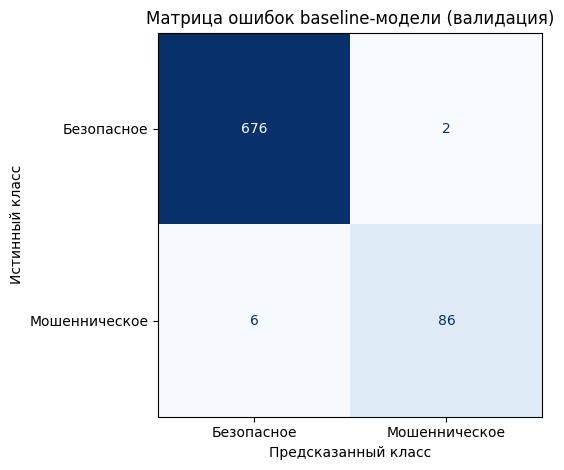

In [4]:
matrix = confusion_matrix(val["label"], val_pred)
display = ConfusionMatrixDisplay(matrix, display_labels=["Безопасное", "Мошенническое"])
display.plot(cmap="Blues", colorbar=False, values_format="d")
display.ax_.set_title("Матрица ошибок baseline-модели (валидация)")
display.ax_.set_xlabel("Предсказанный класс")
display.ax_.set_ylabel("Истинный класс")
display.figure_.tight_layout()
display.figure_.savefig(FIGURES / "baseline_confusion_matrix.png", dpi=130)
plt.show()

## Ошибки: 5 пропусков (FN) и 5 ложных тревог (FP)

In [5]:
errors = val.assign(proba=val_proba, pred=val_pred)
fn = errors[(errors["label"] == 1) & (errors["pred"] == 0)].sort_values("proba").head(5)
fp = errors[(errors["label"] == 0) & (errors["pred"] == 1)].sort_values("proba", ascending=False).head(5)
print(f"Всего FN: {((errors['label'] == 1) & (errors['pred'] == 0)).sum()}, всего FP: {((errors['label'] == 0) & (errors['pred'] == 1)).sum()}\n")
print("FN: мошенничество пропущено")
for row in fn.itertuples():
    print(f"  P={row.proba:.2f} | {row.text_raw}")
print("\nFP: ложная тревога")
for row in fp.itertuples():
    print(f"  P={row.proba:.2f} | {row.text_raw}")
# Настоящих FP меньше пяти, поэтому дополняем список ham с самой высокой вероятностью.
near = errors[(errors["label"] == 0) & (errors["pred"] == 0)].sort_values("proba", ascending=False).head(5 - len(fp))
print("\nНе ошибки, но ближе всего к ложной тревоге:")
for row in near.itertuples():
    print(f"  P={row.proba:.2f} | {row.text_raw}")

Всего FN: 6, всего FP: 2

FN: мошенничество пропущено
  P=0.05 | LIFE has never been this much fun and great until you came in. You made it truly special for me. I won't forget you! enjoy @ one gbp/sms
  P=0.10 | In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)
  P=0.22 | You will be receiving this week's Triple Echo ringtone shortly. Enjoy it!
  P=0.25 | Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!
  P=0.40 | TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the next link sent to ur fone...

FP: ложная тревога
  P=0.86 | Your bill at 3 is £33.65 so thats not bad!
  P=0.64 | Message:some text missing* Sender:Name Missing* *Number Missing *Sent:Date missing *Missing U a lot thats y everything is missing sent via fullons

### Почему модель ошиблась

**Пропуски (FN).** В этих сообщениях нет сильных сигналов: ни телефона, ни суммы, ни ссылки.
- «LIFE has never been...» написано как личное письмо, рекламу выдаёт только «gbp/sms» в конце.
- Викторина про The Simpsons и реклама билетов на Новый год похожи на обычную переписку. Это спам-реклама, а не мошенничество: здесь видно, что spam ≠ мошенничество.
- Сообщения про рингтон и загрузки (TheMob) используют редкую лексику, которой мало в обучении.

**Ложные тревоги (FP).**
- «Your bill at 3 is £33.65» содержит сумму. Токен `<money>` встречается в 51,5% spam и только в 0,3% ham, поэтому модель придаёт ему большой вес.
- Шаблонное сообщение с fullonsms.com содержит адрес сайта, а `<url>` тоже почти не встречается в ham.

**Вывод.** Модель сильно опирается на токены `<money>`, `<phone>` и `<url>`. Мошенник может их обойти, если напишет сообщение без сумм и номеров, поэтому на этапе 2 нужны сравнение алгоритмов и подбор порога (задание 8), а в итоговой оценке риска учитываются ещё правила и анализ ссылок.

## Сохранение и проверка загрузки

In [6]:
ARTIFACTS = ROOT / "ml" / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
joblib.dump(pipeline, ARTIFACTS / "sms_baseline.joblib", compress=3)
meta = {
    "version": "0.1.0-baseline",
    "algorithm": "LogisticRegression(class_weight=balanced, max_iter=1000)",
    "features": ["word_tfidf_1_2", "char_wb_tfidf_3_5"] + HAND_FEATURE_NAMES,
    "threshold": THRESHOLD,
    "metrics_val": {name: round(float(value), 4) for name, value in metrics.items()},
    "trained_at": date.today().isoformat(),
    "train_size": len(train),
}
(ARTIFACTS / "sms_baseline_meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print("Размер файла, МБ:", round((ARTIFACTS / "sms_baseline.joblib").stat().st_size / 1024 ** 2, 2))

Размер файла, МБ: 0.44


In [7]:
loaded = joblib.load(ARTIFACTS / "sms_baseline.joblib")
loaded_proba = loaded.predict_proba(val["text_raw"])[:, 1]
assert np.array_equal(loaded_proba, val_proba)
print("Предсказания загруженной модели полностью совпадают.")

Предсказания загруженной модели полностью совпадают.


## Функция predict_sms на новых текстах

`predict_sms` находится в `ml/predictor.py`: она загружает сохранённый pipeline, а `normalize_sms` вызывается внутри него.

In [8]:
from ml.predictor import predict_sms

for text in [
    "Your order #4821 has been shipped and will arrive on Monday.",
    "Congratulations! You won a $1000 gift card. Claim your prize: bit.ly/prize-claim-test",
    "URGENT: Your account will be suspended in 24 hours. Verify now at http://192.0.2.15/account-update",
    "See you at the library tomorrow at 6",
]:
    print(predict_sms(text), "|", text)

{'label': 0, 'probability': 0.2125} | Your order #4821 has been shipped and will arrive on Monday.
{'label': 1, 'probability': 0.9978} | Congratulations! You won a $1000 gift card. Claim your prize: bit.ly/prize-claim-test
{'label': 1, 'probability': 0.9742} | URGENT: Your account will be suspended in 24 hours. Verify now at http://192.0.2.15/account-update
{'label': 0, 'probability': 0.0546} | See you at the library tomorrow at 6


## Предварительно: русский и казахский наборы

Полная проверка относится к заданию 8. Здесь видно, почему для этих языков ML-оценка отмечается как ненадёжная.

In [9]:
custom = pd.read_csv(ROOT / "data" / "raw" / "custom_ru_kk.csv", encoding="utf-8")
custom["y"] = (custom["label"] == "fraud").astype(int)
custom["pred"] = loaded.predict(custom["text"])
rows = {}
for lang, part in custom.groupby("lang"):
    rows[lang] = {
        "Записей": len(part),
        "Recall мошенничества": recall_score(part["y"], part["pred"], zero_division=0),
        "Precision": precision_score(part["y"], part["pred"], zero_division=0),
        "Доля ложных тревог": part.loc[part["y"] == 0, "pred"].mean(),
    }
print("«Привет! Встречаемся завтра...»:", predict_sms("Привет! Встречаемся завтра в 18:00 у входа в библиотеку."))
pd.DataFrame(rows).T.round(3)

«Привет! Встречаемся завтра...»: {'label': 1, 'probability': 0.9302}


,Записей,Recall мошенничества,Precision,Доля ложных тревог
kk,50.0,0.80,0.645,0.44
ru,100.0,0.84,0.667,0.42


Высокий Recall здесь нельзя считать доказательством поддержки языков: модель просто часто отвечает «мошенничество».
- Большая доля безопасных сообщений получает ложную тревогу; даже обычное приглашение на встречу получает высокую вероятность.
- Вероятная причина: русских и казахских слов нет в словаре TF-IDF. После L2-нормализации весь вес вектора приходится на знакомые токены (`!`, `<num>`), а они в обучении связаны со спамом.
- Набор маленький и написан тем же автором, что и словарь правил, поэтому результаты могут быть завышены.

Поэтому в приложении оценка модели для этих языков помечена как ненадёжная и не входит в Risk Score. Полная проверка выполняется в задании 8.